# Análisis exploratorio de Airbnb Bogotá

Este notebook consulta **MongoDB** como fuente de datos. Antes de ejecutarlo, importa los CSV/GZ del curso en `AirbnbBogota` como `Listings`, `Reviews` y `Calendar`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pymongo import MongoClient
from IPython.display import display


In [2]:
URI = "mongodb://localhost:27017/"
DB_NAME = "AirbnbBogota"
client = MongoClient(URI, serverSelectionTimeoutMS=5000)
client.admin.command("ping")
db = client[DB_NAME]

def leer_coleccion(nombre):
    documentos = list(db[nombre].find({}, {"_id": 0}))
    return pd.json_normalize(documentos, sep="_") if documentos else pd.DataFrame()

listings = leer_coleccion("Listings")
reviews = leer_coleccion("Reviews")
calendar = leer_coleccion("Calendar")
print("Conexión a MongoDB correcta")
print({"Listings": listings.shape, "Reviews": reviews.shape, "Calendar": calendar.shape})


Conexión a MongoDB correcta
{'Listings': (19187, 93), 'Reviews': (527731, 6), 'Calendar': (7003255, 5)}


## 1. Entendimiento general
Se muestran las primeras filas, dimensiones y tipos de datos de cada colección.

In [3]:
for nombre, df in {"Listings": listings, "Reviews": reviews, "Calendar": calendar}.items():
    print(f"\\n--- {nombre} ---")
    display(df.head())
    print("Dimensiones (filas, columnas):", df.shape)
    df.info()


\n--- Listings ---


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,price_quote_raw_quote_discount_amount,price_quote_raw_quote_price_per_night,price_quote_raw_quote_nightly_subtotal,price_quote_raw_quote_discounted_subtotal,price_quote_raw_quote_raw_price_line_items,price_quote_raw_quote_returned_checkin_date,price_quote_raw_quote_requested_checkin_date,price_quote_raw_quote_returned_checkout_date,price_quote_raw_quote_requested_checkout_date,bathrooms
0,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,https://a0.muscache.com/pictures/38377482/1df3...,113734,https://www.airbnb.com/users/show/113734,...,780208.80,284294.0142857142857142857143,NaN,7960232.40,"[{'amount': '8740441.20', 'item_type': 'other'...",NaN,2027-04-01,NaN,2027-04-29,NaN
1,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",https://a0.muscache.com/pictures/miso/Hosting-...,321447,https://www.airbnb.com/users/show/321447,...,NaN,215000,215000.00,215000.00,"[{'amount': '215000.00', 'item_type': 'nightly...",NaN,2026-06-27,NaN,2026-06-28,1.0
2,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,https://a0.muscache.com/pictures/24594394/1ace...,676823,https://www.airbnb.com/users/show/676823,...,859408.20,99196.099,NaN,2975882.97,"[{'amount': '3835291.17', 'item_type': 'other'...",NaN,2026-06-22,NaN,2026-07-22,1.0
3,178850,https://www.airbnb.com/rooms/178850,20260621155658,2026-06-22,city scrape,"MODERN APARTMENT, 3 ROOMS, 4 PAX",NaN,https://a0.muscache.com/pictures/22dabfab-c264...,498646,https://www.airbnb.com/users/show/498646,...,36984.24,179910.6666666666666666666667,NaN,5397319.46,"[{'amount': '5434303.70', 'item_type': 'other'...",NaN,2026-07-04,NaN,2026-08-03,2.0
4,289669,https://www.airbnb.com/rooms/289669,20260621155658,2026-06-22,city scrape,Room near to everything you need in Bogotá!,My house is located in one of the most iconic ...,https://a0.muscache.com/pictures/hosting/Hosti...,1503758,https://www.airbnb.com/users/show/1503758,...,NaN,82260.75,329042.24,329042.24,"[{'amount': '329042.24', 'item_type': 'nightly...",NaN,2026-08-12,NaN,2026-08-16,1.0


Dimensiones (filas, columnas): (19187, 93)
<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 93 columns):
 #   Column                                         Non-Null Count  Dtype         
---  ------                                         --------------  -----         
 0   id                                             19187 non-null  int64         
 1   listing_url                                    19187 non-null  str           
 2   scrape_id                                      19187 non-null  int64         
 3   last_scraped                                   19187 non-null  datetime64[us]
 4   source                                         19187 non-null  str           
 5   name                                           19187 non-null  object        
 6   description                                    18664 non-null  str           
 7   picture_url                                    19187 non-null  str           
 8   host_id                 

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."
3,27841,225796,2011-04-13,471115,Tiffany,Marcela was a lovely and gracious host. She me...
4,27841,952928,2012-02-27,1098411,Sarah,Marcela is the perfect host and has a gorgeuos...


Dimensiones (filas, columnas): (527731, 6)
<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   listing_id     527731 non-null  int64         
 1   id             527731 non-null  int64         
 2   date           527731 non-null  datetime64[us]
 3   reviewer_id    527731 non-null  int64         
 4   reviewer_name  527731 non-null  object        
 5   comments       527730 non-null  object        
dtypes: datetime64[us](1), int64(3), object(2)
memory usage: 24.2+ MB
\n--- Calendar ---


,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,False,2,1125
1,15410909,2026-06-23,False,2,1125
2,15410909,2026-06-24,False,2,1125
3,15410909,2026-06-25,True,2,1125
4,15410909,2026-06-26,True,2,1125


Dimensiones (filas, columnas): (7003255, 5)
<class 'pandas.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Data columns (total 5 columns):
 #   Column          Dtype         
---  ------          -----         
 0   listing_id      int64         
 1   date            datetime64[us]
 2   available       bool          
 3   minimum_nights  int64         
 4   maximum_nights  int64         
dtypes: bool(1), datetime64[us](1), int64(3)
memory usage: 220.4 MB


## 2. Calidad de datos
Los faltantes se cuantifican por columna y los duplicados se identifican antes de decidir si deben eliminarse.

In [10]:
import json
import pandas as pd
from IPython.display import display

def resumen_calidad(df, nombre):
    print(f"\n{nombre}")

    # 1. Valores faltantes
    faltantes = df.isna().sum().sort_values(ascending=False)
    display(faltantes[faltantes > 0].to_frame("faltantes"))

    # 2. Detectar duplicados sin modificar el DataFrame original
    df_comparable = df.copy()

    for columna in df_comparable.columns:
        df_comparable[columna] = df_comparable[columna].map(
            lambda valor: json.dumps(
                valor, sort_keys=True, ensure_ascii=False, default=str
            ) if isinstance(valor, (list, dict)) else valor
        )

    print("Duplicados exactos:", int(df_comparable.duplicated().sum()))

    # 3. Porcentaje de faltantes
    porcentaje = (
        df.isna().mean().mul(100).round(2)
        .sort_values(ascending=False)
    )

    print("Porcentaje de faltantes por columna:")
    display(porcentaje.to_frame("% faltantes"))


for nombre, df in {
    "Listings": listings,
    "Reviews": reviews,
    "Calendar": calendar
}.items():
    resumen_calidad(df, nombre)




Listings


,faltantes
price_quote_raw_quote_returned_checkin_date,19187
price_quote_raw_quote_date_match,19187
price_quote_raw_quote_cleaning_fee,19187
price_quote_raw_quote_service_fee,19187
price_quote_raw_quote_returned_checkout_date,19187
price_quote_raw_quote_taxes,19185
price_quote_raw_quote_discount_amount,14617
host_about,8799
host_location,5157
review_scores_location,4266


Duplicados exactos: 0
Porcentaje de faltantes por columna:


,% faltantes
price_quote_raw_quote_returned_checkin_date,100.0
price_quote_raw_quote_date_match,100.0
price_quote_raw_quote_cleaning_fee,100.0
price_quote_raw_quote_service_fee,100.0
price_quote_raw_quote_returned_checkout_date,100.0
...,...
availability_30,0.0
calculated_host_listings_count_private_rooms,0.0
calculated_host_listings_count_shared_rooms,0.0
calculated_host_listings_count,0.0



Reviews


...

,% faltantes
listing_id,0.0
id,0.0
date,0.0
reviewer_id,0.0
reviewer_name,0.0
comments,0.0



Calendar


,faltantes


Duplicados exactos: 0
Porcentaje de faltantes por columna:


,% faltantes
listing_id,0.0
date,0.0
available,0.0
minimum_nights,0.0
maximum_nights,0.0


## 3. Variables numéricas y posibles valores atípicos
Los valores extremos se identifican con estadísticos descriptivos y diagramas de caja. No se eliminan sin justificación.

Variables numéricas de Listings


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,19187.0,NaN,NaN,NaN,954806690904213632.0,27841.0,576948095111162752.0,1126189903933745408.0,1467539428254577408.0,1712443307406192128.0,603722280461440768.0
listing_url,19187,19187,https://www.airbnb.com/rooms/27841,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scrape_id,19187.0,NaN,NaN,NaN,20260621155658.0,20260621155658.0,20260621155658.0,20260621155658.0,20260621155658.0,20260621155658.0,0.0
last_scraped,19187,NaN,NaN,NaN,2026-06-21 22:10:43.560744,2026-06-21 00:00:00,2026-06-22 00:00:00,2026-06-22 00:00:00,2026-06-22 00:00:00,2026-06-22 00:00:00,NaN
source,19187,1,city scrape,19187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,19187,18135,Impecable habitación con baño privado,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,18664,14583,Enjoy the simplicity of this quiet and central...,203,NaN,NaN,NaN,NaN,NaN,NaN,NaN
picture_url,19187,18457,https://a0.muscache.com/pictures/miso/Hosting-...,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,19187.0,NaN,NaN,NaN,10183653822382740.0,25167.0,100382091.0,274278122.0,494106071.0,1710986775580589312.0,130583555503451440.0
host_url,19187,8335,https://www.airbnb.com/users/show/24945688,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN


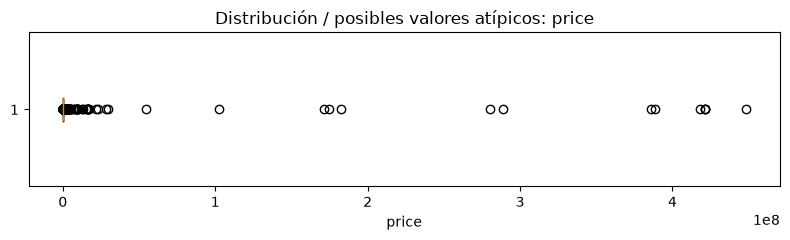

price {'count': 18992.0, 'mean': 446026.5525505476, 'std': 8829056.710912477, 'min': 19181.11, '1%': 37610.03, '25%': 110000.0, '50%': 161460.0, '75%': 230346.375, '99%': 1330087.1317, 'max': 448176567.0}


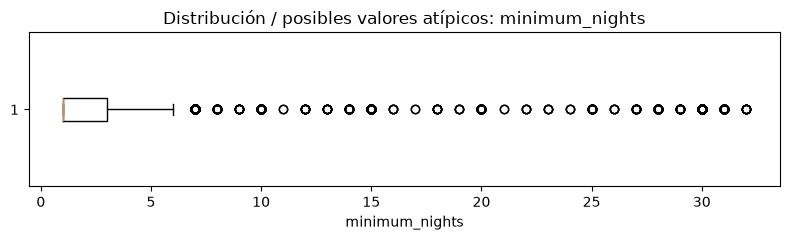

minimum_nights {'count': 19183.0, 'mean': 6.979878016994213, 'std': 10.99398474622734, 'min': 1.0, '1%': 1.0, '25%': 1.0, '50%': 1.0, '75%': 3.0, '99%': 30.0, 'max': 32.0}


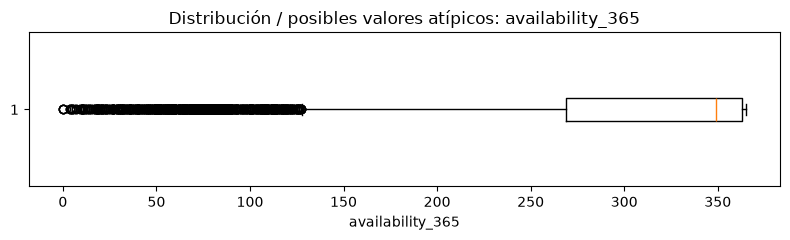

availability_365 {'count': 19187.0, 'mean': 306.9477250221504, 'std': 82.07360125233141, 'min': 0.0, '1%': 49.860000000000014, '25%': 269.0, '50%': 349.0, '75%': 363.0, '99%': 365.0, 'max': 365.0}


In [9]:
print("Variables numéricas de Listings")
display(listings.describe(include="all").T.head(30))

for col in ["price", "minimum_nights", "availability_365"]:
    if col in listings.columns:
        serie = pd.to_numeric(
            listings[col].astype(str).str.replace(r"[$,]", "", regex=True),
            errors="coerce"
        ).dropna()

        if len(serie):
            fig, ax = plt.subplots(figsize=(8, 2.5))

            # Corrección para Matplotlib 3.11+
            ax.boxplot(serie, orientation="horizontal")

            ax.set_title(f"Distribución / posibles valores atípicos: {col}")
            ax.set_xlabel(col)

            plt.tight_layout()
            plt.show()

            print(
                col,
                serie.describe(
                    percentiles=[.01, .25, .5, .75, .99]
                ).to_dict()
            )



## 4. Distribuciones y relaciones
Las gráficas se generan únicamente si existen las columnas esperadas en el dataset.

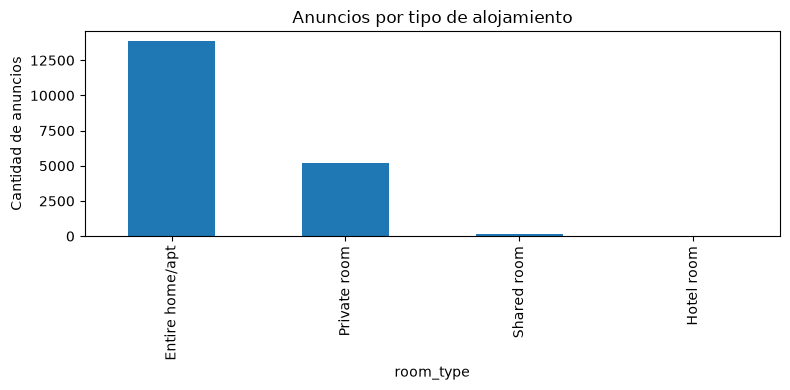

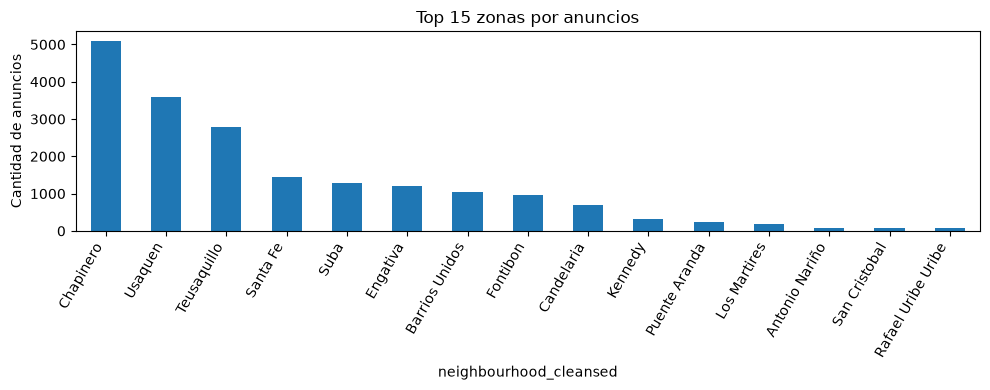

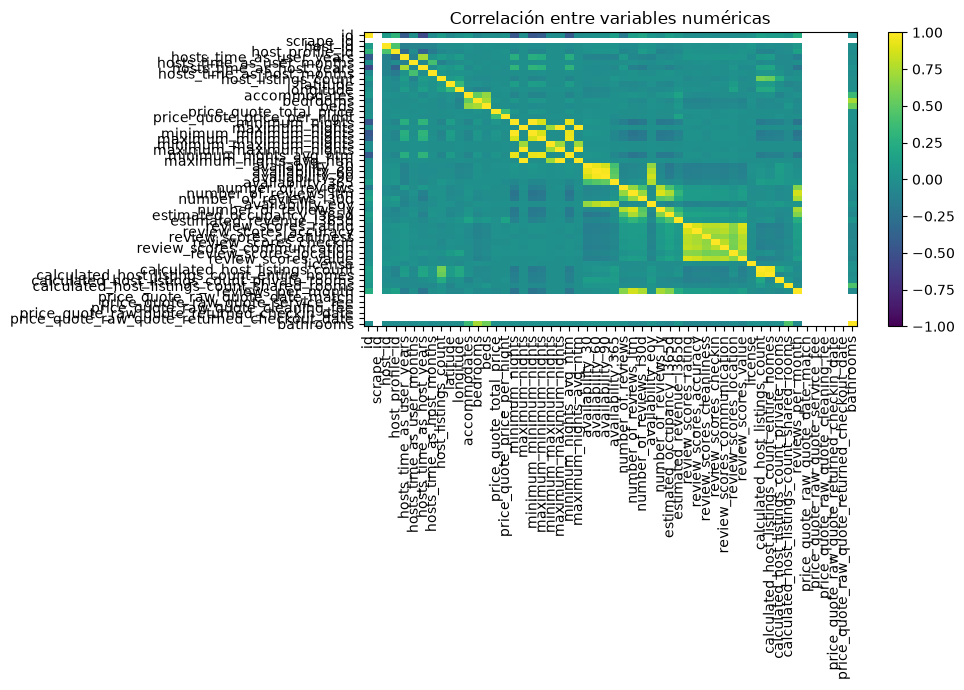

In [6]:
if "room_type" in listings.columns:
    listings["room_type"].value_counts().head(10).plot(kind="bar", figsize=(8,4), title="Anuncios por tipo de alojamiento")
    plt.ylabel("Cantidad de anuncios")
    plt.tight_layout()
    plt.show()

if "neighbourhood_cleansed" in listings.columns:
    listings["neighbourhood_cleansed"].value_counts().head(15).plot(kind="bar", figsize=(10,4), title="Top 15 zonas por anuncios")
    plt.ylabel("Cantidad de anuncios")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()

numeric = listings.select_dtypes(include=np.number)
if numeric.shape[1] >= 2:
    corr = numeric.corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(10,7))
    im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index)
    ax.set_title("Correlación entre variables numéricas")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()


## 5. Calendario por mes
Si existe `date`, se estandariza temporalmente y se resume por mes. El resultado ayuda a observar patrones de disponibilidad/precio.

In [8]:
if "date" in calendar.columns:
    cal = calendar.copy()
    cal["date_parsed"] = pd.to_datetime(cal["date"], errors="coerce")
    print("Fechas no interpretables:", int(cal["date_parsed"].isna().sum()))
    cal["month"] = cal["date_parsed"].dt.to_period("M").astype(str)
    display(cal.groupby("month", dropna=False).size().rename("registros").reset_index().head(24))
    if "available" in cal.columns:
        display(pd.crosstab(cal["month"], cal["available"]).head(24))
else:
    print("La colección Calendar no contiene una columna 'date'; revisar nombres de columnas.")


Fechas no interpretables: 0


,month,registros
0,2026-06,174141
1,2026-07,594797
2,2026-08,594797
3,2026-09,575610
4,2026-10,594797
5,2026-11,575610
6,2026-12,594797
7,2027-01,594797
8,2027-02,537236
9,2027-03,594797


available,False,True
month,,
2026-06,67331,106810
2026-07,138397,456400
2026-08,79698,515099
2026-09,64103,511507
2026-10,83236,511561
2026-11,57035,518575
2026-12,64713,530084
2027-01,66926,527871
2027-02,58484,478752


## 6. Hallazgos y decisiones

Faltantes: 0
Duplicados exactos: 0
No hay necesidad de eliminar duplicados
Valores extremos: Precio mal alto por noche de 448176567, posible valor atipico.
Fechas: 0 fechas no interpretables
No hay necesidad de estandarizar, desanidar campos o agrupar datos para tener entendimiento del proceso y que este funcione correctamente, pero puede dar beneficios a la hora de ejecutar el programa y mejorar la vista general de estos datos.

In [ ]:
client.close()
print("Conexión cerrada.")
